# Air Quality Index (AQI) Trends Analysis

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Creating dummy dataset for demonstration
np.random.seed(42)
dates = pd.date_range(start='2023-01-01', periods=100, freq='D')
pm25 = np.random.normal(loc=35, scale=15, size=100).clip(5, 150)
pm10 = pm25 * 1.5 + np.random.normal(loc=10, scale=5, size=100)
co = np.random.uniform(0.1, 2.5, size=100)
aqi = pm25 * 1.8 + np.random.normal(loc=20, scale=10, size=100)
aqi = np.clip(aqi, 10, 300)

df_mock = pd.DataFrame({
    'Date': dates,
    'PM2.5': pm25,
    'PM10': pm10,
    'CO': co,
    'AQI': aqi
})
df_mock.to_csv('City_Air_Quality.csv', index=False)
print("Generated mock 'City_Air_Quality.csv' successfully.")

Generated mock 'City_Air_Quality.csv' successfully.


## Load and Explore Dataset

In [2]:
df = pd.read_csv('City_Air_Quality.csv')
df['Date'] = pd.to_datetime(df['Date'])

display(df.info())
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    100 non-null    datetime64[us]
 1   PM2.5   100 non-null    float64       
 2   PM10    100 non-null    float64       
 3   CO      100 non-null    float64       
 4   AQI     100 non-null    float64       
dtypes: datetime64[us](1), float64(4)
memory usage: 4.0 KB


None

,Date,PM2.5,PM10,CO,AQI
0,2023-01-01,42.450712,66.599215,2.205695,94.893431
1,2023-01-02,32.926035,57.285827,1.877845,85.150036
2,2023-01-03,44.715328,75.359420,1.772838,103.297509
3,2023-01-04,57.845448,92.756785,1.785962,117.894811
4,2023-01-05,31.487699,56.425121,0.962779,74.596636


## Visualizing Overall AQI Trend Over Time

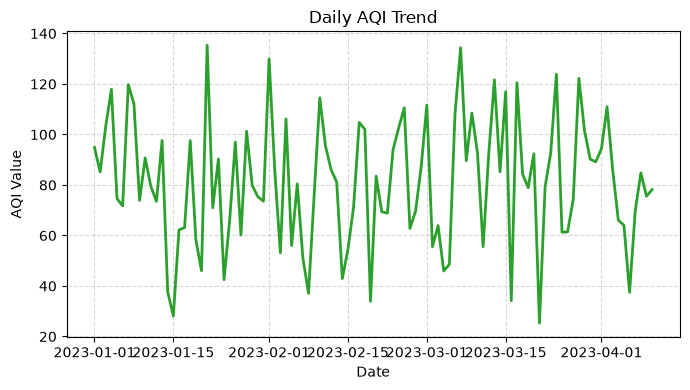

In [3]:
plt.figure(figsize=(7, 4))
plt.plot(df['Date'], df['AQI'], color='#2ca02c', linewidth=2)
plt.title('Daily AQI Trend')
plt.xlabel('Date')
plt.ylabel('AQI Value')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Trends of Individual Pollutants (PM2.5, PM10, CO)

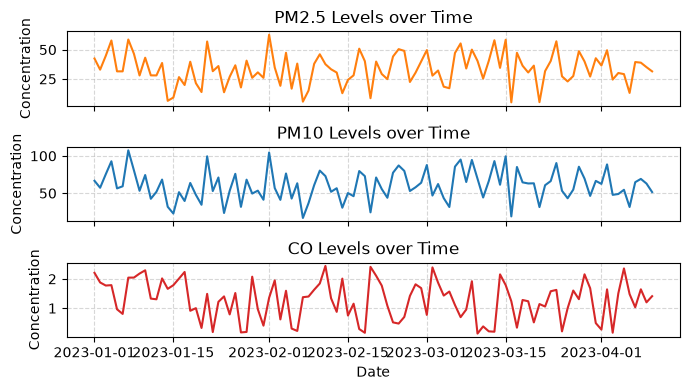

In [4]:
fig, axs = plt.subplots(3, 1, figsize=(7, 4), sharex=True)

axs[0].plot(df['Date'], df['PM2.5'], color='#ff7f0e')
axs[0].set_title('PM2.5 Levels over Time')
axs[0].set_ylabel('Concentration')
axs[0].grid(True, linestyle='--', alpha=0.5)

axs[1].plot(df['Date'], df['PM10'], color='#1f77b4')
axs[1].set_title('PM10 Levels over Time')
axs[1].set_ylabel('Concentration')
axs[1].grid(True, linestyle='--', alpha=0.5)

axs[2].plot(df['Date'], df['CO'], color='#d62728')
axs[2].set_title('CO Levels over Time')
axs[2].set_xlabel('Date')
axs[2].set_ylabel('Concentration')
axs[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

## Comparing Average AQI Across Months

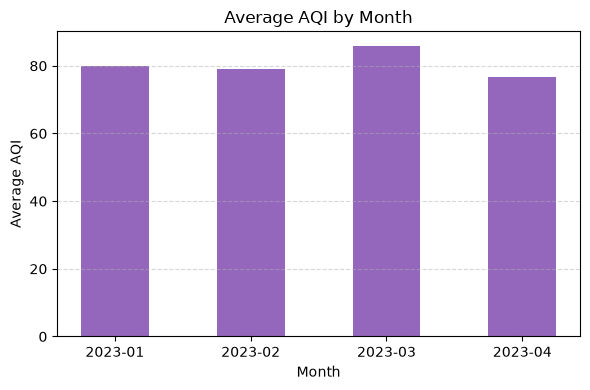

In [5]:
df['Month'] = df['Date'].dt.strftime('%Y-%m')
monthly_aqi = df.groupby('Month')['AQI'].mean().reset_index()

plt.figure(figsize=(6, 4))
plt.bar(monthly_aqi['Month'], monthly_aqi['AQI'], color='#9467bd', width=0.5)
plt.title('Average AQI by Month')
plt.xlabel('Month')
plt.ylabel('Average AQI')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Distribution of AQI Values

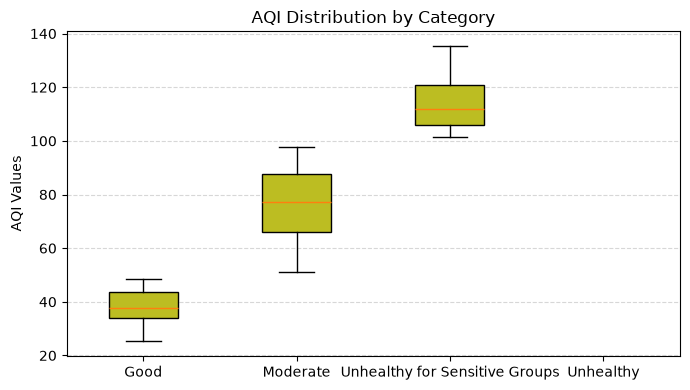

In [6]:
def get_category(aqi_val):
    if aqi_val <= 50: return 'Good'
    elif aqi_val <= 100: return 'Moderate'
    elif aqi_val <= 150: return 'Unhealthy for Sensitive Groups'
    else: return 'Unhealthy'

df['Category'] = df['AQI'].apply(get_category)
categories = ['Good', 'Moderate', 'Unhealthy for Sensitive Groups', 'Unhealthy']
data_to_plot = [df[df['Category'] == cat]['AQI'] for cat in categories]

plt.figure(figsize=(7, 4))
plt.boxplot(data_to_plot, tick_labels=categories, patch_artist=True,
            boxprops=dict(facecolor='#bcbd22', color='black'))
plt.title('AQI Distribution by Category')
plt.ylabel('AQI Values')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Relationship between AQI and Pollutant Levels

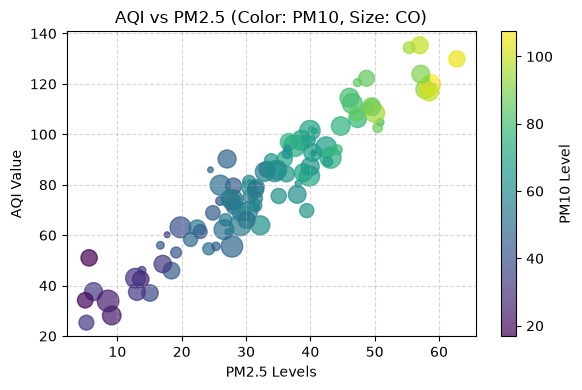

In [7]:
plt.figure(figsize=(6, 4))
scatter = plt.scatter(df['PM2.5'], df['AQI'], c=df['PM10'], cmap='viridis', s=df['CO']*100, alpha=0.7)
plt.title('AQI vs PM2.5 (Color: PM10, Size: CO)')
plt.xlabel('PM2.5 Levels')
plt.ylabel('AQI Value')
cbar = plt.colorbar(scatter)
cbar.set_label('PM10 Level')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()